# 04 · Selección de variables para el clustering (issue #12 · ML-01)

**Objetivo:** decidir qué indicadores del dataset v0.3 entran en el clustering municipal, cuáles no y por qué, y cómo se tratan las escalas y las ausencias.

Este notebook **no entrena ningún modelo**: solo analiza las 36 variables. La decisión final está en `docs/methodology/seleccion_variables_ml.md`.

Para ejecutarlo necesitas haber generado antes `data/processed/sitewise_v03` con los notebooks 01, 02 y 03.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data').is_dir() and (p / 'notebooks').is_dir())
DATA = ROOT / 'data/processed/sitewise_v03'
assert (DATA / 'valores.csv').exists(), 'Genera antes el dataset con los notebooks 01, 02 y 03'

pd.set_option('display.max_rows', 100)
pd.set_option('display.width', 200)
print('Datos en:', DATA.relative_to(ROOT))

Datos en: data\processed\sitewise_v03


## 1. Cargar el diccionario y los valores

`cod_ine` se lee como texto para conservar los ceros iniciales. `valor` vacío significa desconocido: el motivo está en la columna `estado`.

In [2]:
indicadores = pd.read_csv(DATA / 'indicadores.csv')
municipios = pd.read_csv(DATA / 'municipios.csv', dtype={'cod_ine': str, 'cod_provincia': str})
valores = pd.read_csv(DATA / 'valores.csv', dtype={'cod_ine': str}, low_memory=False,
                      usecols=['cod_ine', 'id_indicador', 'valor', 'estado'])
valores['valor'] = pd.to_numeric(valores['valor'], errors='coerce')

print(f'{len(municipios):,} municipios · {len(indicadores)} indicadores · {len(valores):,} registros')
indicadores[['id_indicador', 'bloque', 'tipo', 'unidad', 'nivel_origen']]

8,132 municipios · 36 indicadores · 292,752 registros


,id_indicador,bloque,tipo,unidad,nivel_origen
0,poblacion_2024,demografia,contexto,personas,municipio
1,poblacion_2025,demografia,contexto,personas,municipio
2,variacion_poblacion_pct,demografia,contexto,%,municipio
3,densidad_hab_km2,demografia,contexto,habitantes/km2,municipio
4,cobertura_ftth_pct,infraestructura_digital,atractivo,% hogares,municipio
5,cobertura_100mbps_pct,infraestructura_digital,atractivo,% hogares,municipio
6,cobertura_1gbps_pct,infraestructura_digital,atractivo,% hogares,municipio
7,cobertura_5g_pct,infraestructura_digital,atractivo,% hogares,municipio
8,tiepi_horas_prov_2021,infraestructura_electrica,riesgo,horas equivalentes,provincia
9,niepi_prov_2021,infraestructura_electrica,riesgo,interrupciones equivalentes,provincia


## 2. Cobertura: cuántos municipios tienen dato en cada variable

K-Means no admite huecos. Una variable con poca cobertura obliga a inventar muchos valores (imputar) o a quitar muchos municipios.

In [3]:
g = valores.groupby('id_indicador')
cobertura = pd.DataFrame({
    'con_valor': g['valor'].apply(lambda s: s.notna().sum()),
    'cobertura_pct': g['valor'].apply(lambda s: round(100 * s.notna().mean(), 1)),
    'valores_distintos': g['valor'].nunique(),
    'ceros_pct': g['valor'].apply(lambda s: round(100 * (s == 0).mean(), 1)),
    'estados': g['estado'].apply(lambda s: '; '.join(f'{k}: {v}' for k, v in s.value_counts().items())),
}).join(indicadores.set_index('id_indicador')[['bloque', 'nivel_origen']])
cobertura.sort_values('cobertura_pct')

,con_valor,cobertura_pct,valores_distintos,ceros_pct,estados,bloque,nivel_origen
id_indicador,,,,,,,
eventos_cnih_2000_2023_n,2480,30.5,16,0.0,pendiente: 5652; real: 2480,amenazas_naturales,municipio
ultimo_anio_cnih_2000_2023,2480,30.5,17,0.0,pendiente: 5652; real: 2480,amenazas_naturales,municipio
paro_construccion,3095,38.1,294,7.5,publicado: 3094; blanco_fuente: 2629; ocultado...,empleo,municipio
paro_sin_empleo_anterior,3104,38.2,372,5.8,publicado: 3104; blanco_fuente: 2789; ocultado...,empleo,municipio
paro_agricultura,3113,38.3,183,13.5,publicado: 3113; ocultado_menor5: 2569; blanco...,empleo,municipio
paro_industria,3527,43.4,316,9.3,publicado: 3526; ocultado_menor5: 2492; blanco...,empleo,municipio
superficie_forestal_afectada_2006_2015_ha,4375,53.8,756,0.0,real: 4375; pendiente: 3757,amenazas_naturales,municipio
ha_afectadas_100km2_2006_2015,4375,53.8,4375,0.0,real: 4375; pendiente: 3757,amenazas_naturales,municipio
siniestros_forestales_2006_2015_n,4375,53.8,264,0.0,real: 4375; pendiente: 3757,amenazas_naturales,municipio


**Qué se ve:**

- Empleo (paro y contratos): entre el 38 % y el 77 %. El SEPE oculta las cifras menores de 5 y deja celdas en blanco.
- Inundaciones (CNIH): 30 %. Incendios (EGIF): 54 %.
- TIEPI y NIEPI tienen dato en todos los municipios, pero solo unos 50 valores distintos: es el dato de la provincia repetido.
    - **TIEPI** (*Tiempo de Interrupción Equivalente de la Potencia Instalada*): cuántas horas al año se va la luz.
    - **NIEPI** (*Número de Interrupciones Equivalente de la Potencia Instalada*): cuántas veces al año se va la luz.
    - "Equivalente de la potencia instalada" significa que pesan más los cortes que afectan a más potencia contratada: un corte en un polígono industrial cuenta más que en una casa aislada.
- El resto está por encima del 91 %.

## 3. ¿Las ausencias son aleatorias?

Si los huecos se concentran en un tipo de municipio, rellenarlos con cero o quitarlos sesga el resultado.

In [4]:
ancho = valores.pivot(index='cod_ine', columns='id_indicador', values='valor')
ancho = ancho.join(municipios.set_index('cod_ine')[['superficie_km2']])

for var, comparar in [('ha_afectadas_100km2_2006_2015', 'superficie_km2'),
                      ('eventos_cnih_2000_2023_n', 'poblacion_2025')]:
    sin_dato = ancho[var].isna()
    print(f'{var}: mediana de {comparar}  ·  sin dato = {ancho.loc[sin_dato, comparar].median():,.0f}'
          f'  ·  con dato = {ancho.loc[~sin_dato, comparar].median():,.0f}')

ha_afectadas_100km2_2006_2015: mediana de superficie_km2  ·  sin dato = 23  ·  con dato = 51
eventos_cnih_2000_2023_n: mediana de poblacion_2025  ·  sin dato = 261  ·  con dato = 3,527


**Conclusión:** no son aleatorias. Los municipios sin dato de incendios son más pequeños, y los que no tienen inundaciones registradas tienen mucha menos población. Que no haya registro **no demuestra** que no haya riesgo (lo advierte Elena en `docs/data/sitewise_v03/METODOLOGIA.md`). Convertir esos huecos en cero haría que los municipios pequeños parecieran más seguros solo porque se miden peor.

## 4. Variables redundantes

Si dos variables dicen casi lo mismo, el tema pesa doble en el clustering. Se usa la correlación de Spearman (por rangos), que no depende de la escala ni de valores extremos. Las variables con mucha asimetría se pasan a logaritmo antes.

- **Por qué Spearman y no Pearson:** *Spearman* compara posiciones (rangos), no valores. Por eso no le afectan los valores extremos ni las variables muy sesgadas, como la población, que va de unas decenas de habitantes a 3 millones.
- **Por qué logaritmo:** variables como la densidad o las distancias tienen unos pocos valores enormes. Sin el logaritmo, esos pocos municipios dominarían el clustering.

In [5]:
candidatas = ['poblacion_2025', 'densidad_hab_km2', 'variacion_poblacion_pct',
              'cobertura_ftth_pct', 'cobertura_100mbps_pct', 'cobertura_1gbps_pct', 'cobertura_5g_pct',
              'irradiacion_ghi_kwh_m2_anio', 'viento_100m_media_m_s',
              'estres_hidrico_pct', 'agotamiento_hidrico_pct', 'superficie_estres_ge40_pct',
              'dist_recta_ttm_km', 'dist_recta_ttm_intermodal_km', 'dist_recta_eje_autovia_km',
              'suelo_industrial_cartografiado_pct', 'suelo_industrial_cartografiado_ha',
              'tiepi_horas_prov_2021', 'niepi_prov_2021', 'paro_total']
a_log = ['poblacion_2025', 'densidad_hab_km2', 'suelo_industrial_cartografiado_ha', 'paro_total',
         'dist_recta_ttm_km', 'dist_recta_ttm_intermodal_km', 'dist_recta_eje_autovia_km']

X = ancho[candidatas].copy()
X[a_log] = np.log1p(X[a_log])
corr = X.corr(method='spearman')

pares = [(a, b, corr.loc[a, b]) for i, a in enumerate(candidatas) for b in candidatas[i + 1:]
         if abs(corr.loc[a, b]) >= 0.7]
pd.DataFrame(pares, columns=['variable_a', 'variable_b', 'rho']).sort_values('rho', key=abs, ascending=False).round(2)

,variable_a,variable_b,rho
7,estres_hidrico_pct,agotamiento_hidrico_pct,0.99
11,suelo_industrial_cartografiado_pct,suelo_industrial_cartografiado_ha,0.98
2,poblacion_2025,paro_total,0.97
5,cobertura_ftth_pct,cobertura_1gbps_pct,0.89
0,poblacion_2025,densidad_hab_km2,0.85
10,dist_recta_ttm_km,dist_recta_ttm_intermodal_km,0.85
4,cobertura_ftth_pct,cobertura_100mbps_pct,0.81
3,densidad_hab_km2,paro_total,0.78
8,estres_hidrico_pct,superficie_estres_ge40_pct,0.77
9,agotamiento_hidrico_pct,superficie_estres_ge40_pct,0.77


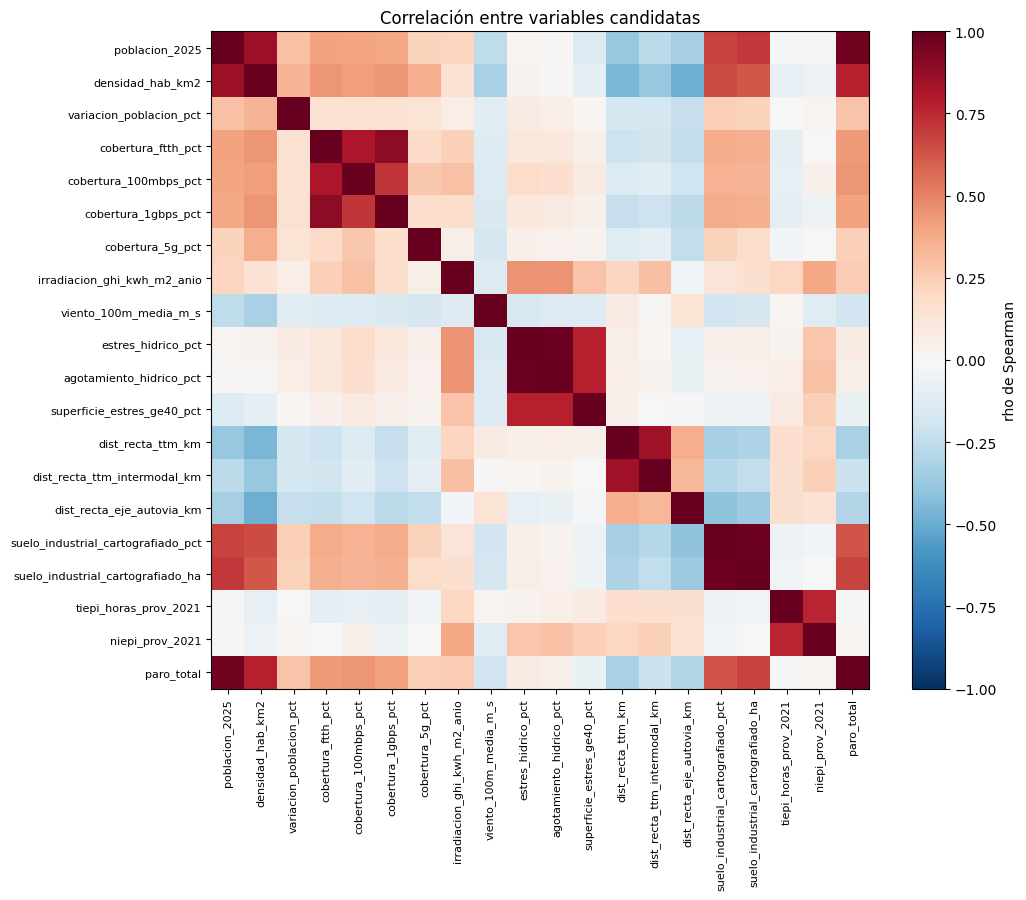

In [6]:
fig, ax = plt.subplots(figsize=(11, 9))
im = ax.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(candidatas)), candidatas, rotation=90, fontsize=8)
ax.set_yticks(range(len(candidatas)), candidatas, fontsize=8)
fig.colorbar(im, ax=ax, label='rho de Spearman')
ax.set_title('Correlación entre variables candidatas')
plt.tight_layout()
plt.show()

## 5. Propuesta de variables (versión 1)

Criterios, en este orden:

1. **Cobertura** de al menos el 98 % de los municipios.
2. **Dato propio del municipio** (o de una rejilla fina), no el de la provincia repetido.
3. **Sin redundancias:** de cada grupo muy correlacionado se queda una variable.
4. **Describe el territorio**, no el tamaño: proporciones y densidades mejor que totales.

In [7]:
propuesta = pd.DataFrame([
    # variable, decisión, transformación, motivo
    ('densidad_hab_km2', 'entra', 'log', 'Demografía. Representa también a la población (rho 0,85)'),
    ('variacion_poblacion_pct', 'entra', 'recortar p1-p99', 'Dinamismo demográfico: zonas que crecen o se vacían'),
    ('cobertura_ftth_pct', 'entra', '-', 'Conectividad fija. Representa a 1 Gbps (0,89) y 100 Mbps (0,81)'),
    ('cobertura_5g_pct', 'entra', '-', 'Conectividad móvil, no redundante con la fija'),
    ('irradiacion_ghi_kwh_m2_anio', 'entra', '-', 'Recurso solar'),
    ('viento_100m_media_m_s', 'entra', '-', 'Recurso eólico (2 municipios sin dato)'),
    ('estres_hidrico_pct', 'entra', '-', 'Agua. Representa a agotamiento (0,99) y superficie con estrés (0,77)'),
    ('dist_recta_eje_autovia_km', 'entra', 'log', 'Logística por carretera'),
    ('dist_recta_ttm_km', 'entra', 'log', 'Logística ferroviaria. Representa a la intermodal (0,85)'),
    ('suelo_industrial_cartografiado_pct', 'entra', '-', 'Suelo industrial. El 0 es "sin polígonos en el catálogo"'),
    ('poblacion_2024', 'no entra', '', 'Redundante con 2025 y mide tamaño'),
    ('poblacion_2025', 'no entra', '', 'Mide tamaño; la densidad ya la representa'),
    ('cobertura_100mbps_pct', 'no entra', '', 'Redundante con FTTH'),
    ('cobertura_1gbps_pct', 'no entra', '', 'Redundante con FTTH'),
    ('agotamiento_hidrico_pct', 'no entra', '', 'Redundante con estrés hídrico'),
    ('superficie_estres_ge40_pct', 'no entra', '', 'Redundante con estrés hídrico'),
    ('dist_recta_ttm_intermodal_km', 'no entra', '', 'Redundante con terminal de mercancías'),
    ('suelo_industrial_cartografiado_ha', 'no entra', '', 'Redundante con el % y mide tamaño'),
    ('tiepi_horas_prov_2021', 'no entra', '', 'Dato provincial repetido: agruparía por provincias'),
    ('niepi_prov_2021', 'no entra', '', 'Dato provincial repetido: agruparía por provincias'),
    ('ultimo_anio_cnih_2000_2023', 'no entra', '', 'Es un año, no una medida de riesgo'),
    ('paro_total', 'no entra', '', '77 % de cobertura y cifras ocultas (<5); mide tamaño'),
    ('paro_agricultura', 'no entra', '', '38 % de cobertura'),
    ('paro_industria', 'no entra', '', '43 % de cobertura'),
    ('paro_construccion', 'no entra', '', '38 % de cobertura'),
    ('paro_servicios', 'no entra', '', '72 % de cobertura'),
    ('paro_sin_empleo_anterior', 'no entra', '', '38 % de cobertura'),
    ('contratos_total', 'no entra', '', '58 % de cobertura'),
    ('paro_variacion_interanual_pct', 'no entra', '', '71 % de cobertura'),
    ('siniestros_forestales_2006_2015_n', 'pendiente', '', '54 %: ausencias no aleatorias. Decidir con Elena'),
    ('superficie_forestal_afectada_2006_2015_ha', 'pendiente', '', '54 %: ausencias no aleatorias. Decidir con Elena'),
    ('siniestros_forestales_100km2_2006_2015', 'pendiente', '', '54 %: ausencias no aleatorias. Decidir con Elena'),
    ('ha_afectadas_100km2_2006_2015', 'pendiente', '', '54 %: ausencias no aleatorias. Decidir con Elena'),
    ('eventos_cnih_2000_2023_n', 'pendiente', '', '30 %: ausencias no aleatorias. Decidir con Elena'),
    ('agua_subterranea_mal_estado_cuantitativo_pct', 'pendiente', '', '91 %: sin masa catalogada no es bueno ni malo'),
    ('agua_subterranea_mal_estado_quimico_pct', 'pendiente', '', '91 %: sin masa catalogada no es bueno ni malo'),
], columns=['id_indicador', 'decision', 'transformacion', 'motivo'])

assert set(propuesta.id_indicador) == set(indicadores.id_indicador), 'Faltan o sobran indicadores en la propuesta'
print(propuesta.decision.value_counts().to_string())
propuesta.merge(cobertura[['cobertura_pct']], left_on='id_indicador', right_index=True)

decision
no entra     19
entra        10
pendiente     7


,id_indicador,decision,transformacion,motivo,cobertura_pct
0,densidad_hab_km2,entra,log,Demografía. Representa también a la población ...,100.0
1,variacion_poblacion_pct,entra,recortar p1-p99,Dinamismo demográfico: zonas que crecen o se v...,100.0
2,cobertura_ftth_pct,entra,-,"Conectividad fija. Representa a 1 Gbps (0,89) ...",100.0
3,cobertura_5g_pct,entra,-,"Conectividad móvil, no redundante con la fija",100.0
4,irradiacion_ghi_kwh_m2_anio,entra,-,Recurso solar,100.0
5,viento_100m_media_m_s,entra,-,Recurso eólico (2 municipios sin dato),100.0
6,estres_hidrico_pct,entra,-,"Agua. Representa a agotamiento (0,99) y superf...",99.7
7,dist_recta_eje_autovia_km,entra,log,Logística por carretera,99.3
8,dist_recta_ttm_km,entra,log,Logística ferroviaria. Representa a la intermo...,98.0
9,suelo_industrial_cartografiado_pct,entra,-,"Suelo industrial. El 0 es ""sin polígonos en el...",100.0


## 6. Comprobación final de las 10 variables que entran

Cuántos municipios quedarían con todas las variables completas, y qué huecos hay que tratar.

In [8]:
entran = propuesta.loc[propuesta.decision == 'entra', 'id_indicador'].tolist()
huecos = ancho[entran].isna().sum()
completos = ancho[entran].notna().all(axis=1).sum()
print(f'Municipios con las {len(entran)} variables completas: {completos:,} de {len(ancho):,} ({100 * completos / len(ancho):.1f} %)')
huecos[huecos > 0].rename('municipios_sin_dato').to_frame()

Municipios con las 10 variables completas: 7,951 de 8,132 (97.8 %)


,municipios_sin_dato
viento_100m_media_m_s,2
estres_hidrico_pct,24
dist_recta_eje_autovia_km,56
dist_recta_ttm_km,161


Los huecos que quedan son pocos y tienen explicación: municipios sin terminal o sin autovía catalogada "en tierra" (sobre todo en islas), sin cobertura suficiente en el modelo de agua o sin dato de viento. El tratamiento propuesto está en el documento de metodología.